<a href="https://colab.research.google.com/github/iliyadindar/DEEP/blob/main/week10/stereo_odev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hafta 10 — Stereo Eşleştirme

**Grup: Nmertgules ve Iliya**

Veri: Middlebury 2001 **Tsukuba** sahnesi ([tsukuba.zip](https://vision.middlebury.edu/stereo/data/scenes2001/data/tsukuba/tsukuba.zip)). Ödevde istendiği gibi 1. ve 3. resimler kullanıldı: `scene1.row3.col1.ppm` (sol) ve `scene1.row3.col3.ppm` (sağ). Görüntüler zaten rektifiye (rectified), yani eşlenik noktalar aynı satırda.

**Referans görüntü neden sağ (col3)?** Zip içindeki gerçek fark haritası (`truedisp.row3.col3.pgm`) col3 görüntüsü için verilmiş. Ölçüm yapabilmek için bütün yöntemlerin fark haritasını col3 koordinatlarında hesapladık. Sağdaki bir piksel `x`, soldaki görüntüde `x + d` konumunda görünür. OpenCV eşleştiricileri sol görüntüyü referans alır; onlara iki görüntüyü yatay çevirip yer değiştirerek veriyoruz, çıktıyı tekrar çeviriyoruz (aynı şey, sadece ayna).

**Gerçek fark değerleri:** `truedisp` dosyası komşu iki kamera (col3–col4) için ve 16 ile çarpılmış saklanıyor. col1 ile col3 arasında iki kamera adımı olduğu için fark iki katı: `gt = truedisp / 16 * 2`, yani 10–28 piksel. Değeri 0 olan pikseller bilinmiyor (kenarlar), ölçüme katılmıyor.

**Ölçüt:** `kötü piksel %` = gerçek farkı bilinen piksellerden hatası 2 pikselden büyük olanların veya hiç değer üretilmeyenlerin oranı (2 px bu çift için, komşu kamera ölçeğinde 1 px'e denk). `MAE` sadece değer üretilen piksellerde ortalama mutlak hata.

In [1]:
import time, zipfile, io, urllib.request
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt

# notebook week10 klasöründen, repo kökünden veya Colab'dan çalışabilsin
if Path.cwd().name == 'week10':
    HAFTA = Path('.')
elif Path('week10').is_dir():
    HAFTA = Path('week10')
else:
    HAFTA = Path('.')
ASSETS, SONUC = HAFTA / 'assets', HAFTA / 'results'
ASSETS.mkdir(exist_ok=True); SONUC.mkdir(exist_ok=True)

dosyalar = {'scene1.row3.col1.ppm': 'tsukuba_col1.png',
            'scene1.row3.col3.ppm': 'tsukuba_col3.png',
            'truedisp.row3.col3.pgm': 'tsukuba_truedisp_col3.png'}
if not all((ASSETS / b).exists() for b in dosyalar.values()):
    url = 'https://vision.middlebury.edu/stereo/data/scenes2001/data/tsukuba/tsukuba.zip'
    print('[BİLGİ] tsukuba.zip indiriliyor...')
    z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
    for a, b in dosyalar.items():
        im = cv2.imdecode(np.frombuffer(z.read(a), np.uint8), cv2.IMREAD_UNCHANGED)
        cv2.imwrite(str(ASSETS / b), im)

sol_renkli = cv2.imread(str(ASSETS / 'tsukuba_col1.png'))
sag_renkli = cv2.imread(str(ASSETS / 'tsukuba_col3.png'))
sol = cv2.cvtColor(sol_renkli, cv2.COLOR_BGR2GRAY)
sag = cv2.cvtColor(sag_renkli, cv2.COLOR_BGR2GRAY)
gt = cv2.imread(str(ASSETS / 'tsukuba_truedisp_col3.png'), 0).astype(np.float32) / 16 * 2
GT_GECERLI = gt > 0

H, W = sag.shape
MAKS_D = 32   # gerçek fark en fazla 28, StereoBM 16'nın katı istiyor
print(f'Görüntü: {W}x{H}, gerçek fark aralığı: {gt[GT_GECERLI].min():.0f}-{gt.max():.0f} px, '
      f'bilinen piksel: %{100 * GT_GECERLI.mean():.1f}')

Görüntü: 384x288, gerçek fark aralığı: 10-28 px, bilinen piksel: %79.3


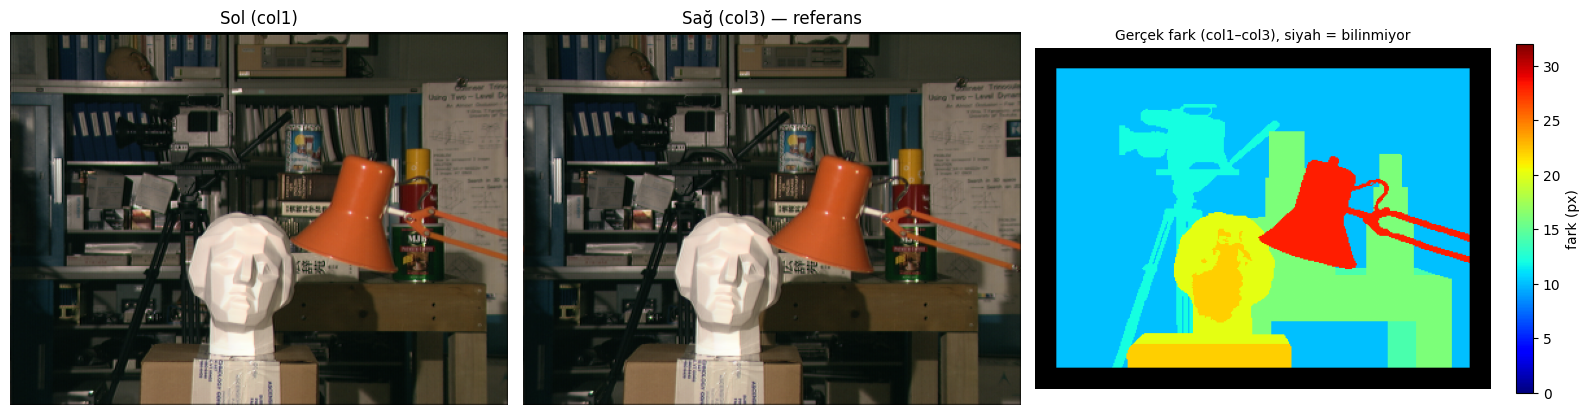

In [2]:
def degerlendir(d, maske=None):
    """kötü piksel % (hata > 2 px veya değer yok), MAE ve kapsama % döndürür."""
    v = GT_GECERLI if maske is None else (GT_GECERLI & maske)
    dv, gv = d[v], gt[v]
    var = np.isfinite(dv) & (dv >= 0)
    hata = np.abs(dv - gv)
    kotu = (~var) | (hata > 2)
    return 100 * kotu.mean(), hata[var].mean(), 100 * var.mean()

def fark_goster(ax, d, baslik):
    g = np.ma.masked_where(~np.isfinite(d) | (d < 0), d)
    cmap = plt.get_cmap('jet').copy(); cmap.set_bad('black')
    im = ax.imshow(g, cmap=cmap, vmin=0, vmax=MAKS_D)
    ax.set_title(baslik, fontsize=10); ax.axis('off')
    return im

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].imshow(cv2.cvtColor(sol_renkli, cv2.COLOR_BGR2RGB)); ax[0].set_title('Sol (col1)'); ax[0].axis('off')
ax[1].imshow(cv2.cvtColor(sag_renkli, cv2.COLOR_BGR2RGB)); ax[1].set_title('Sağ (col3) — referans'); ax[1].axis('off')
im = fark_goster(ax[2], np.where(GT_GECERLI, gt, np.nan), 'Gerçek fark (col1–col3), siyah = bilinmiyor')
fig.colorbar(im, ax=ax[2], fraction=0.035, label='fark (px)')
plt.tight_layout(); plt.show()

## Görev 1 — OpenCV StereoBM ve StereoSGBM ile fark haritası

`StereoBM` her piksel için sabit boyutlu bir pencereyi (blok) diğer görüntüde aynı satır boyunca kaydırır ve SAD'si en küçük olan kaymayı fark (disparity) olarak alır. `StereoSGBM` aynı maliyete ek olarak komşu piksellerin farkları arasındaki atlamaları cezalandırır (Görev 4'te kendimiz yazıyoruz). İki eşleştirici de farkı 16 ile çarpılmış `int16` döndürür, 16'ya bölüyoruz.

OpenCV StereoBM (blok 15)    süre    1.9 ms | kötü piksel % 23.5 | MAE 0.85 px | kapsama % 81.8
OpenCV StereoSGBM (blok 5)   süre    7.6 ms | kötü piksel % 12.3 | MAE 0.74 px | kapsama % 92.4


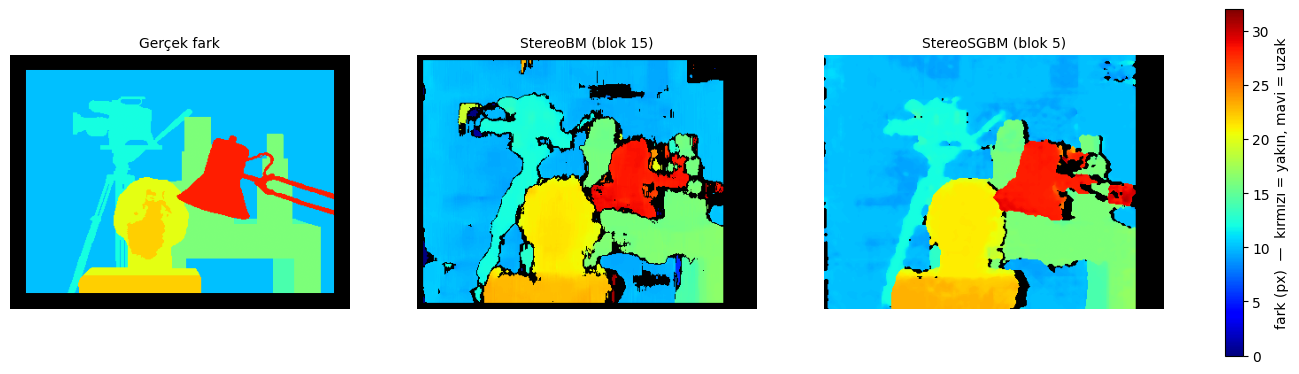

In [3]:
def opencv_sag_referans(eslestirici, sol, sag):
    """OpenCV sol görüntüyü referans alır: görüntüleri aynalayıp yer değiştiriyoruz,
    çıkan haritayı tekrar aynalayınca col3 (sağ) koordinatlarında fark elde ediliyor."""
    d = eslestirici.compute(np.ascontiguousarray(sag[:, ::-1]),
                            np.ascontiguousarray(sol[:, ::-1])).astype(np.float32) / 16
    d = d[:, ::-1].copy()
    d[d < 0] = np.nan        # eşleşme bulunamayan pikseller (-1)
    return d

bm = cv2.StereoBM_create(numDisparities=MAKS_D, blockSize=15)
blok_sgbm = 5
sgbm = cv2.StereoSGBM_create(minDisparity=0, numDisparities=MAKS_D, blockSize=blok_sgbm,
                             P1=8 * blok_sgbm**2, P2=32 * blok_sgbm**2,
                             uniquenessRatio=10, speckleWindowSize=100, speckleRange=2,
                             mode=cv2.STEREO_SGBM_MODE_SGBM)

sonuclar = {}   # yöntem -> (fark haritası, süre ms); ev ödevinde de kullanılacak
for ad, es in [('OpenCV StereoBM (blok 15)', bm), ('OpenCV StereoSGBM (blok 5)', sgbm)]:
    opencv_sag_referans(es, sol, sag)                     # ısınma
    t0 = time.perf_counter()
    for _ in range(5):
        d = opencv_sag_referans(es, sol, sag)
    sure = (time.perf_counter() - t0) / 5 * 1000
    sonuclar[ad] = (d, sure)
    kotu, mae, kap = degerlendir(d)
    print(f'{ad:28s} süre {sure:6.1f} ms | kötü piksel %{kotu:5.1f} | MAE {mae:4.2f} px | kapsama %{kap:5.1f}')

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
fark_goster(ax[0], np.where(GT_GECERLI, gt, np.nan), 'Gerçek fark')
fark_goster(ax[1], sonuclar['OpenCV StereoBM (blok 15)'][0], 'StereoBM (blok 15)')
im = fark_goster(ax[2], sonuclar['OpenCV StereoSGBM (blok 5)'][0], 'StereoSGBM (blok 5)')
fig.colorbar(im, ax=list(ax), fraction=0.02, label='fark (px)  —  kırmızı = yakın, mavi = uzak')
plt.savefig(SONUC / 'gorev1_bm_sgbm.png', dpi=110, bbox_inches='tight'); plt.show()

### Görev 1 — Yorum

**Renklerin anlamı.** Renk, pikselin fark (disparity) değerini gösteriyor: iki görüntüde aynı noktanın kaç piksel kaydığı. Fark derinlikle ters orantılı, o yüzden **kırmızı = büyük fark = kameraya yakın**, **mavi = küçük fark = uzak**. Tsukuba'da en yakın nesne lamba (kırmızı, ~26 px), sonra heykel başı ve önündeki masa (sarı–turuncu, ~20–22 px), kamera ve arkadaki raf (açık mavi–yeşil, ~12–16 px), en uzakta arka duvar (mavi, ~10 px). Siyah pikseller için eşleştirici değer üretemedi:

- sağ kenardaki şerit: col3'teki bu sütunların karşılığı col1'de görüntünün dışında kalıyor (en fazla 31 piksel arandığı için),
- nesne kenarlarının yanındaki ince siyah bölgeler: **örtülme (occlusion)**; bu pikseller sadece bir kamerada görünüyor,
- StereoBM'de arka duvardaki ve tavan lambasının çevresindeki delikler: **dokusuz bölgeler**; blokların hepsi birbirine benzediği için eşleşme belirsiz, `uniquenessRatio`/doku eşiği bunları atıyor.

StereoBM (blok 15) nesne kenarlarını şişiriyor (lamba ve baş olduğundan büyük) ve %18 pikselde hiç değer üretmiyor (kötü piksel %23,5'in çoğu bu). StereoSGBM (blok 5) çok daha düzgün: %92 kapsama, kötü piksel %12,3, kenarlar daha keskin. Süre: BM ~2 ms, SGBM ~8 ms.

**Gerçek bir derinlik ölçümü sağlıyor mu?** Tek başına hayır. Fark haritası sadece **göreli** derinlik veriyor (hangi nesne daha yakın). Metre cinsinden derinlik için $Z = \dfrac{f \cdot B}{d}$ formülünde odak uzaklığı $f$ (piksel) ve iki kamera arası mesafe $B$ (baseline) gerekiyor, bunlar kamera kalibrasyonundan gelir; Tsukuba zip'inde bu bilgiler yok. Ayrıca:

- fark tamsayı (BM) veya 1/16 adımlı; uzak nesnelerde $d$ küçük olduğu için 1 piksellik hata derinlikte büyük hataya dönüşür ($\Delta Z \approx Z^2 \Delta d / (fB)$),
- örtülen ve dokusuz bölgelerde değer yok veya yanlış,
- görüntülerin rektifiye olduğu varsayılıyor; gerçek bir kamera çiftinde önce kalibrasyon + rektifikasyon yapılmalı.

Kalibre edilmiş bir kamera çiftinde ise ($f$, $B$ biliniyorsa, örn. `cv2.reprojectImageTo3D` ile) fark haritası gerçek derinliğe çevrilebilir.

## Görev 2 — Kendi blok eşleştirme fonksiyonumuz (StereoBM kullanmadan)

Fikir StereoBM ile aynı: her aday fark `d` (0 … 31) için sol görüntüyü `d` piksel sola kaydırıp sağ görüntüyle piksel piksel karşılaştırıyoruz, bu farkları `blok × blok` pencerede topluyoruz ve her piksel için maliyeti en küçük `d`'yi seçiyoruz.

Pencere toplamını her piksel için ayrı ayrı döngüyle hesaplamak çok yavaş olur (384 × 288 × 32 × blok²). Bunun yerine **integral görüntü** (`cumsum`) kullandık: bir pencerenin toplamı 4 değerin toplama/çıkarmasıyla bulunuyor, pencere boyutundan bağımsız. Böylece döngü sadece `d` üzerinde dönüyor, geri kalanı NumPy ile vektörel.

Fonksiyon, maliyet fonksiyonunu parametre olarak alıyor (`maliyet_fn`). Böylece Görev 3'te sadece fonksiyonu değiştirerek SAD, SSD ve ZNCC'yi deneyebiliyoruz.

Kendi BM, SAD, blok  5: süre   98.0 ms | kötü piksel % 19.5 | MAE 2.00 px
Kendi BM, SAD, blok  9: süre   94.3 ms | kötü piksel % 14.4 | MAE 1.57 px
Kendi BM, SAD, blok 15: süre  106.7 ms | kötü piksel % 12.5 | MAE 1.41 px


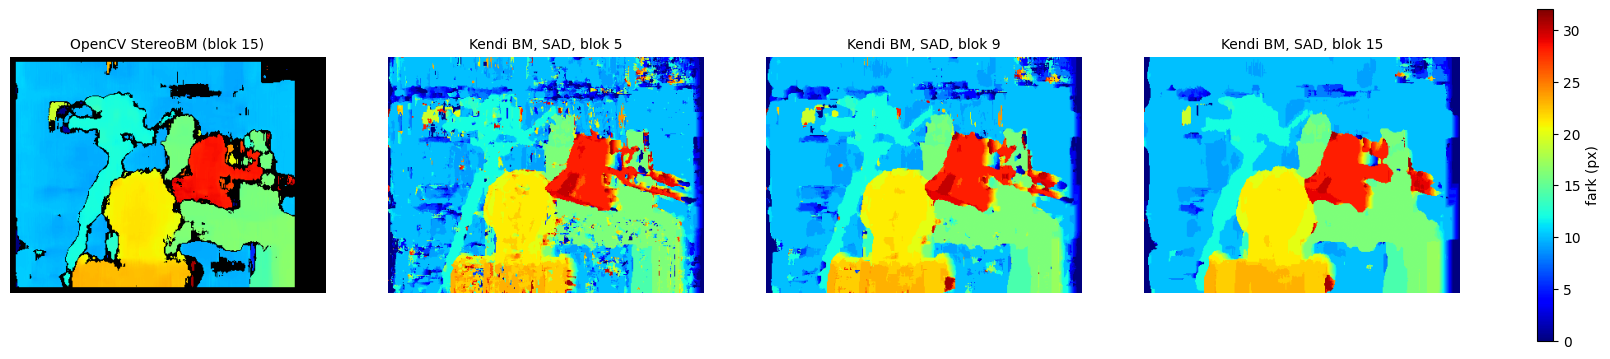

In [4]:
def kutu_ortalama(a, k):
    """k x k pencere ortalaması, integral görüntü ile (kenarlar tekrar edilerek doldurulur)."""
    r = k // 2
    p = np.pad(a.astype(np.float64), ((r + 1, r), (r + 1, r)), mode='edge')
    ii = p.cumsum(0).cumsum(1)
    s = ii[k:, k:] - ii[:-k, k:] - ii[k:, :-k] + ii[:-k, :-k]
    return (s / (k * k)).astype(np.float32)

def sola_kaydir(img, d):
    """out[:, x] = img[:, x + d]; görüntü dışına taşan sütunlar son sütunla doldurulur."""
    if d == 0:
        return img
    return np.concatenate([img[:, d:], np.repeat(img[:, -1:], d, axis=1)], axis=1)

def sad(ref, aday, k):
    return kutu_ortalama(np.abs(ref - aday), k)

def maliyet_hacmi(sag, sol, maks_d, blok, maliyet_fn=sad):
    """C[y, x, d] = sağdaki (x) blok ile soldaki (x + d) blok arasındaki maliyet."""
    ref = sag.astype(np.float32); aday = sol.astype(np.float32)
    C = np.empty((H, W, maks_d), np.float32)
    for d in range(maks_d):
        C[:, :, d] = maliyet_fn(ref, sola_kaydir(aday, d), blok)
        C[:, W - d:, d] = np.inf          # x + d görüntünün dışında: eşleşme yok
    return C

def blok_eslestir(sag, sol, maks_d=MAKS_D, blok=9, maliyet_fn=sad):
    C = maliyet_hacmi(sag, sol, maks_d, blok, maliyet_fn)
    d = C.argmin(axis=2).astype(np.float32)
    d[~np.isfinite(C.min(axis=2))] = np.nan
    return d

for blok in [5, 9, 15]:
    t0 = time.perf_counter()
    d = blok_eslestir(sag, sol, blok=blok)
    sure = (time.perf_counter() - t0) * 1000
    sonuclar[f'Kendi BM, SAD (blok {blok})'] = (d, sure)
    kotu, mae, kap = degerlendir(d)
    print(f'Kendi BM, SAD, blok {blok:2d}: süre {sure:6.1f} ms | kötü piksel %{kotu:5.1f} | MAE {mae:4.2f} px')

fig, ax = plt.subplots(1, 4, figsize=(20, 4.3))
fark_goster(ax[0], sonuclar['OpenCV StereoBM (blok 15)'][0], 'OpenCV StereoBM (blok 15)')
for a, blok in zip(ax[1:], [5, 9, 15]):
    im = fark_goster(a, sonuclar[f'Kendi BM, SAD (blok {blok})'][0], f'Kendi BM, SAD, blok {blok}')
fig.colorbar(im, ax=list(ax), fraction=0.015, label='fark (px)')
plt.savefig(SONUC / 'gorev2_kendi_bm.png', dpi=110, bbox_inches='tight'); plt.show()

### Görev 2 — Yorum

Kendi fonksiyonumuz StereoBM ile aynı mantıkta çalışıyor ve benzer bir harita veriyor. Blok büyüdükçe harita düzgünleşiyor (kötü piksel: blok 5 → %19,5, blok 9 → %14,4, blok 15 → %12,5), ama nesne kenarları kalınlaşıyor ve lambanın ince kolu gibi küçük yapılar kayboluyor. Küçük blok ayrıntıyı koruyor ama dokusuz bölgelerde gürültülü. Bu blok eşleştirmenin temel ödünleşimi (trade-off).

OpenCV ile farklar:

- StereoBM emin olmadığı pikselleri atıyor (doku eşiği, `uniquenessRatio`, sol–sağ kontrolü); bizimki her pikselde argmin'i yazıyor (%100 kapsama), bu yüzden dokusuz bölgelerde rastgele değerler var. Aynı blok boyutunda (15) bizim kötü piksel oranımız daha düşük (%12,5'e karşı %23,5), çünkü OpenCV'nin attığı pikseller ölçütte "kötü" sayılıyor.
- StereoBM alt-piksel (subpixel) fark veriyor, bizimki tamsayı. Bu yüzden MAE'si daha düşük (0,85 px'e karşı 1,41 px).
- Hız: OpenCV ~2 ms (C++, SIMD), bizimki ~100 ms (NumPy). Integral görüntü sayesinde süre blok boyutundan neredeyse bağımsız; doğrudan toplamayla blok 15'te 225 kat daha fazla toplama gerekirdi.

## Görev 3 — Blok benzerliği: SAD, SSD ve ZNCC

Üç fonksiyonun imzası aynı: `(ref, aday, k) -> maliyet haritası` (küçük = daha benzer). `blok_eslestir` hangisini kullanacağını parametre olarak alıyor. Python'da fonksiyon da bir nesne olduğu için bu, C++'taki fonksiyon pointer'ının karşılığı (`float (*maliyet)(const Mat&, const Mat&, int)`).

- **SAD** (Sum of Absolute Differences): $\sum |I_R - I_L|$
- **SSD** (Sum of Squared Differences): $\sum (I_R - I_L)^2$
- **ZNCC** (Zero-mean Normalized Cross-Correlation): $\dfrac{\sum (I_R-\bar I_R)(I_L-\bar I_L)}{\sqrt{\sum (I_R-\bar I_R)^2 \sum (I_L-\bar I_L)^2}}$, $[-1, 1]$ aralığında; maliyet olarak $1 - \text{ZNCC}$ kullanıyoruz.

Parlaklık farkına dayanıklılığı da görmek için ikinci bir deney yaptık: sol görüntünün kontrastını ve parlaklığını değiştirdik (`0.7 · sol + 40`, iki kamera farklı pozlamış gibi) ve aynı eşleştirmeyi tekrarladık.

yöntem blok |  süre ms | kötü % (normal) |   MAE | kötü % (parlaklık farkı)
SAD       5 |    104.4 |            19.5 |  2.00 |                     70.5


SAD       9 |     96.9 |            14.4 |  1.57 |                     61.9
SAD      15 |     94.3 |            12.5 |  1.41 |                     53.1


SSD       5 |     87.0 |            19.9 |  2.06 |                     67.0
SSD       9 |    101.6 |            15.9 |  1.71 |                     55.6


SSD      15 |    100.7 |            14.8 |  1.57 |                     44.4


ZNCC      5 |    327.9 |            24.9 |  2.65 |                     25.5


ZNCC      9 |    319.4 |            15.8 |  1.81 |                     15.9


ZNCC     15 |    346.7 |            13.9 |  1.56 |                     14.0


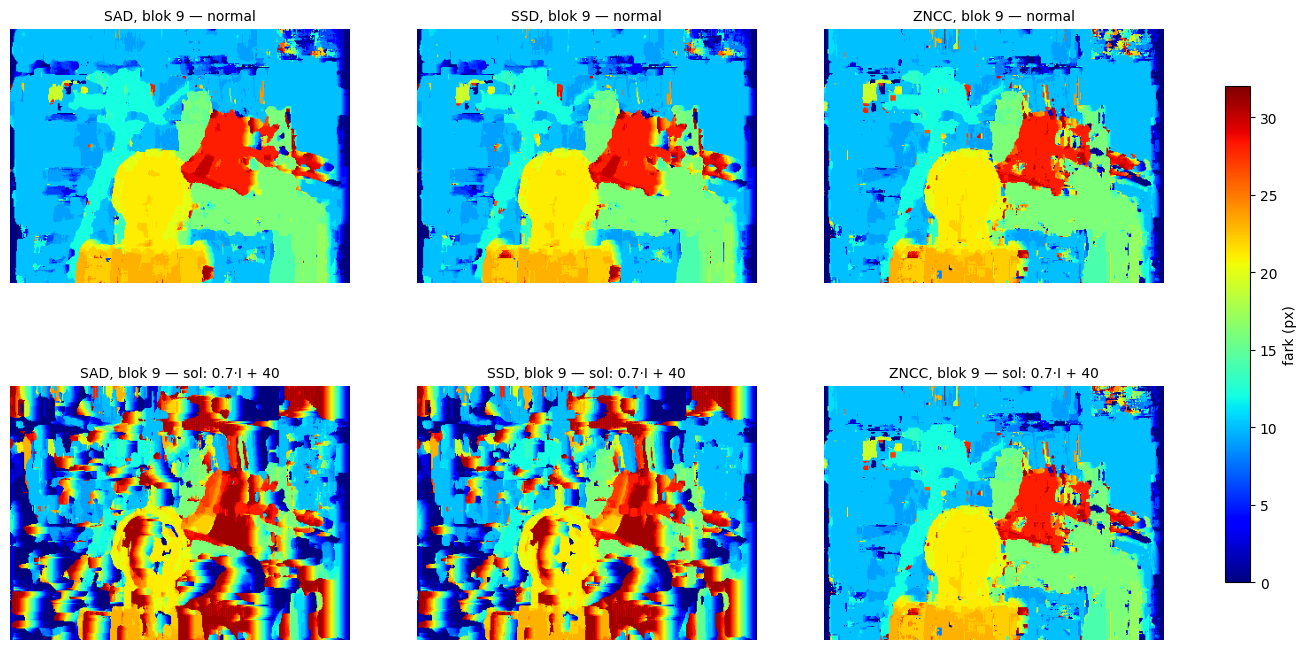

In [5]:
def ssd(ref, aday, k):
    return kutu_ortalama((ref - aday) ** 2, k)

def zncc(ref, aday, k):
    mr, ma = kutu_ortalama(ref, k), kutu_ortalama(aday, k)
    kov = kutu_ortalama(ref * aday, k) - mr * ma
    vr = kutu_ortalama(ref * ref, k) - mr * mr
    va = kutu_ortalama(aday * aday, k) - ma * ma
    return 1 - kov / np.sqrt(np.maximum(vr * va, 1e-6))   # düz bölgede payda ~0, küçük epsilon

maliyetler = {'SAD': sad, 'SSD': ssd, 'ZNCC': zncc}
sol_parlak = np.clip(0.7 * sol.astype(np.float32) + 40, 0, 255).astype(np.uint8)

print(f'{"yöntem":6s} {"blok":>4s} | {"süre ms":>8s} | {"kötü % (normal)":>15s} | {"MAE":>5s} | {"kötü % (parlaklık farkı)":>24s}')
tablo3 = {}
for ad, fn in maliyetler.items():
    for blok in [5, 9, 15]:
        t0 = time.perf_counter()
        d = blok_eslestir(sag, sol, blok=blok, maliyet_fn=fn)
        sure = (time.perf_counter() - t0) * 1000
        d2 = blok_eslestir(sag, sol_parlak, blok=blok, maliyet_fn=fn)
        k1, mae, _ = degerlendir(d); k2, _, _ = degerlendir(d2)
        tablo3[(ad, blok)] = (d, d2)
        sonuclar[f'Kendi BM, {ad} (blok {blok})'] = (d, sure)
        print(f'{ad:6s} {blok:4d} | {sure:8.1f} | {k1:15.1f} | {mae:5.2f} | {k2:24.1f}')

fig, ax = plt.subplots(2, 3, figsize=(16, 8.5))
for j, ad in enumerate(maliyetler):
    fark_goster(ax[0, j], tablo3[(ad, 9)][0], f'{ad}, blok 9 — normal')
    im = fark_goster(ax[1, j], tablo3[(ad, 9)][1], f'{ad}, blok 9 — sol: 0.7·I + 40')
fig.colorbar(im, ax=ax.ravel().tolist(), fraction=0.02, label='fark (px)')
plt.savefig(SONUC / 'gorev3_sad_ssd_zncc.png', dpi=110, bbox_inches='tight'); plt.show()

### Görev 3 — Sonuçlar ve karşılaştırma

Normal görüntü çiftinde (iki kamera aynı pozlamada) SAD en iyi sonucu verdi, SSD ve ZNCC biraz geride. Ama sol görüntünün parlaklığı ve kontrastı değişince (`0.7·I + 40`) SAD ve SSD çöktü: blok 9'da SAD %14,4 → %61,9, SSD %15,9 → %55,6. ZNCC ise hemen hemen hiç etkilenmedi (%15,8 → %15,9). Çünkü ZNCC blok ortalamasını çıkarıp standart sapmaya bölüyor, yani $aI + b$ türü doğrusal parlaklık değişimlerine karşı tamamen değişmez. Bunun bedeli süre: ZNCC her `d` için 5 kutu filtresi istiyor, SAD/SSD 1 tane; bizim kodda ~3 kat daha yavaş (~330 ms'ye karşı ~105 ms).

| Yöntem | Avantajlar | Dezavantajlar |
| --- | --- | --- |
| **SAD** | En basit ve en hızlı (sadece çıkarma ve mutlak değer, çarpma yok); donanımda/SIMD'de kolay. Aykırı değerlere (gürültü, örtülme) SSD'den daha az duyarlı. Bu deneyde normal çiftte en iyi sonuç (%12,5, blok 15). | Parlaklık/kontrast farkına çok duyarlı (%14 → %62). Dokusuz bölgelerde belirsiz. |
| **SSD** | Hızlı; Gauss gürültüsü varsayımı altında istatistiksel olarak en uygun ölçüt (en küçük kareler). Türevlenebilir, alt-piksel kestirimde kullanışlı. | Kare aldığı için büyük farklar (aykırı değer, örtülme kenarları) maliyete fazla ağırlık veriyor; normal çiftte SAD'den biraz kötü. Parlaklık farkına yine duyarlı (%16 → %56). |
| **ZNCC** | Doğrusal parlaklık ve kontrast değişimlerine değişmez: farklı pozlanmış kameralarda bile çalışıyor (%15,8 → %15,9). Sonuç [-1, 1] aralığında, eşik koymak kolay ("güven" ölçüsü). | En yavaş (ortalama, varyans, kovaryans; karekök ve bölme). Dokusuz bölgede varyans ≈ 0 olduğu için kararsız (küçük blokta en kötü: blok 5'te %24,9). Normal çiftte SAD'den biraz kötü. |

Kısaca: kameralar aynı ayarlardaysa SAD hız/doğruluk açısından en iyisi; parlaklık farkı olabiliyorsa (farklı kameralar, otomatik pozlama) ZNCC tercih edilmeli. Üç yöntemde de blok büyüdükçe sonuç iyileşiyor ama kenarlar kalınlaşıyor.

*Not:* Fonksiyonların imzası aynı olduğu için `blok_eslestir(..., maliyet_fn=zncc)` şeklinde fonksiyonu parametre olarak verdik; C++'ta bu `typedef float (*MaliyetFn)(const cv::Mat&, const cv::Mat&, int);` ile fonksiyon pointer'ı olarak yapılırdı.

## Görev 4 — Semi-Global eşleştirmeyi (SGM / SGBM) kendimiz yazıyoruz

Ödevde "SGBC" yazıyor; OpenCV'deki `StereoSGBM`'in temeli olan **Semi-Global (Block) Matching** algoritmasını kastettiğini düşündük (Hirschmüller, 2008).

Blok eşleştirme her pikselin farkını komşularından bağımsız seçiyor, bu yüzden düz (dokusuz) bölgelerde gürültülü. SGM, enerji fonksiyonunu minimize etmeye çalışır:

$$E(D) = \sum_p C(p, D_p) + \sum_{q \in N_p} P_1 \, [\,|D_p - D_q| = 1\,] + \sum_{q \in N_p} P_2 \, [\,|D_p - D_q| > 1\,]$$

Bunu 2B'de tam çözmek zor (NP-zor), o yüzden birkaç doğrultuda 1B dinamik programlama yapıp sonuçları topluyor. Her doğrultu `r` için:

$$L_r(p, d) = C(p, d) + \min\big(L_r(p-r, d),\ L_r(p-r, d\pm1) + P_1,\ \min_k L_r(p-r, k) + P_2\big) - \min_k L_r(p-r, k)$$

Sonra $S(p, d) = \sum_r L_r(p, d)$ ve her piksel için $\arg\min_d S$. Biz 4 doğrultu kullandık (soldan sağa, sağdan sola, yukarıdan aşağı, aşağıdan yukarı). Pikselden piksele döngü yerine bir doğrultudaki bütün satırları (veya sütunları) aynı anda NumPy ile ilerletiyoruz. Ham maliyet olarak 5 × 5 SAD (piksel başına ortalama mutlak fark, 0–255) kullandık.

In [6]:
def sgm_yol(C, P1, P2):
    """C: (adım, n, D). Birinci eksen boyunca ilerleyen 1B dinamik programlama."""
    L = np.empty_like(C)
    L[0] = C[0]
    for i in range(1, C.shape[0]):
        onceki = L[i - 1]
        m = onceki.min(axis=1, keepdims=True)
        bir_asagi = np.full_like(onceki, np.inf); bir_asagi[:, 1:] = onceki[:, :-1] + P1
        bir_yukari = np.full_like(onceki, np.inf); bir_yukari[:, :-1] = onceki[:, 1:] + P1
        L[i] = C[i] + np.minimum(np.minimum(onceki, m + P2), np.minimum(bir_asagi, bir_yukari)) - m
    return L

def sgm(sag, sol, maks_d=MAKS_D, blok=5, P1=10, P2=120, maliyet_fn=sad):
    C = maliyet_hacmi(sag, sol, maks_d, blok, maliyet_fn)
    gecersiz = ~np.isfinite(C)
    C[gecersiz] = 255.0                   # inf yol boyunca yayılmasın: en kötü maliyet
    Ct = C.transpose(1, 0, 2)             # (W, H, D): yatay yollar için
    S = (sgm_yol(Ct, P1, P2) + sgm_yol(Ct[::-1], P1, P2)[::-1]).transpose(1, 0, 2)
    S += sgm_yol(C, P1, P2) + sgm_yol(C[::-1], P1, P2)[::-1]
    d = S.argmin(axis=2).astype(np.float32)
    d[gecersiz.all(axis=2) | gecersiz[np.arange(H)[:, None], np.arange(W)[None, :], d.astype(int)]] = np.nan
    return d

t0 = time.perf_counter()
d_sgm = sgm(sag, sol, P1=10, P2=120)
sure = (time.perf_counter() - t0) * 1000
sonuclar['Kendi SGM (P1=10, P2=120)'] = (d_sgm, sure)
d_sgm_med = cv2.medianBlur(np.nan_to_num(d_sgm, nan=-1).astype(np.float32), 5)
d_sgm_med[d_sgm_med < 0] = np.nan

for ad, d in [('Kendi BM, SAD (blok 5)', sonuclar['Kendi BM, SAD (blok 5)'][0]),
              ('Kendi SGM (P1=10, P2=120)', d_sgm),
              ('Kendi SGM + 5x5 medyan', d_sgm_med),
              ('OpenCV StereoSGBM (blok 5)', sonuclar['OpenCV StereoSGBM (blok 5)'][0])]:
    kotu, mae, kap = degerlendir(d)
    print(f'{ad:28s} kötü piksel %{kotu:5.1f} | MAE {mae:4.2f} px | kapsama %{kap:5.1f}')
print(f'Kendi SGM süresi: {sure:.0f} ms')

Kendi BM, SAD (blok 5)       kötü piksel % 19.5 | MAE 2.00 px | kapsama %100.0
Kendi SGM (P1=10, P2=120)    kötü piksel %  7.8 | MAE 0.92 px | kapsama %100.0
Kendi SGM + 5x5 medyan       kötü piksel %  7.7 | MAE 0.90 px | kapsama %100.0
OpenCV StereoSGBM (blok 5)   kötü piksel % 12.3 | MAE 0.74 px | kapsama % 92.4
Kendi SGM süresi: 234 ms


  P1    P2 |  kötü % |   MAE | süreksizlik %


   0     0 |    19.5 |  2.00 |          15.7


   2     8 |    10.1 |  1.20 |           4.8


  10    40 |     7.5 |  0.98 |           3.5


  10   120 |     7.8 |  0.92 |           3.3


  10   400 |     9.2 |  0.95 |           3.6


  40  2000 |    12.8 |  1.17 |           3.2


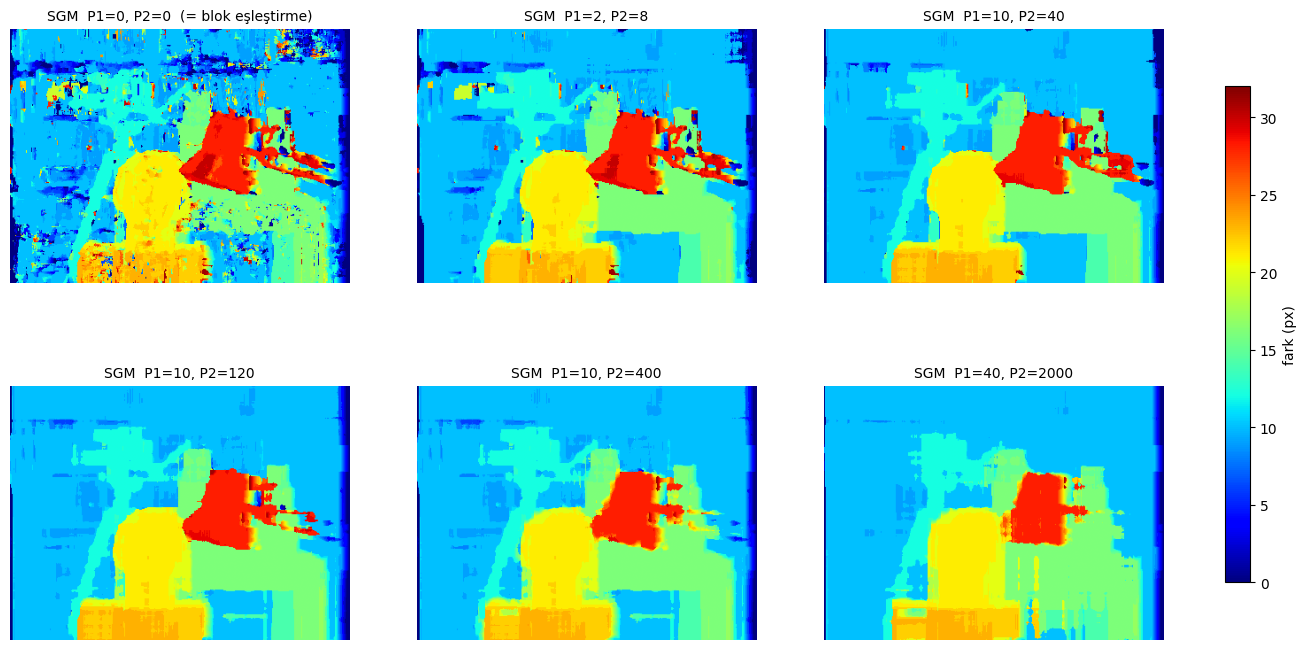

In [7]:
# yumuşaklık (smoothness) parametrelerinin etkisi
ayarlar = [(0, 0), (2, 8), (10, 40), (10, 120), (10, 400), (40, 2000)]
haritalar = {}
print(f'{"P1":>4s} {"P2":>5s} | {"kötü %":>7s} | {"MAE":>5s} | {"süreksizlik %":>13s}')
for P1, P2 in ayarlar:
    d = sgm(sag, sol, P1=P1, P2=P2)
    haritalar[(P1, P2)] = d
    kotu, mae, _ = degerlendir(d)
    # komşusuyla 1'den fazla farklı olan piksel oranı: haritanın ne kadar "parçalı" olduğu
    sicrama = 100 * np.nanmean(np.abs(np.diff(d, axis=1)) > 1)
    print(f'{P1:4d} {P2:5d} | {kotu:7.1f} | {mae:5.2f} | {sicrama:13.1f}')

fig, ax = plt.subplots(2, 3, figsize=(16, 8.5))
for a, (P1, P2) in zip(ax.ravel(), ayarlar):
    im = fark_goster(a, haritalar[(P1, P2)], f'SGM  P1={P1}, P2={P2}' + ('  (= blok eşleştirme)' if P2 == 0 else ''))
fig.colorbar(im, ax=ax.ravel().tolist(), fraction=0.02, label='fark (px)')
plt.savefig(SONUC / 'gorev4_sgm_yumusaklik.png', dpi=110, bbox_inches='tight'); plt.show()

### Görev 4 — Sonuçlar ve yumuşaklık (smoothness) parametresi

Kendi SGM'imiz (P1 = 10, P2 = 120) aynı 5 × 5 SAD maliyetiyle blok eşleştirmenin kötü piksel oranını **%19,5'ten %7,8'e** indirdi. Dokusuz bölgelerdeki (arka duvar, masa) gürültü neredeyse tamamen kayboldu, çünkü bir pikselin farkı artık komşu yollardan gelen bilgiyle seçiliyor. OpenCV StereoSGBM %12,3 kötü piksel verdi, ama onun farkı büyük ölçüde emin olmadığı %8 pikseli atmasından geliyor; değer ürettiği piksellerde alt-piksel hassasiyeti sayesinde MAE'si daha düşük (0,74 px'e karşı 0,92 px). Bizim SGM ~200 ms sürüyor (OpenCV ~8 ms).

**Smoothness parametresi ne işe yarıyor?** Enerji fonksiyonundaki $P_1$ ve $P_2$, komşu pikseller arasındaki fark değişimini cezalandıran yumuşaklık terimi:

- **$P_1$**: komşu pikselin farkı 1 değişirse verilen küçük ceza. Eğik yüzeylerin (masa, zemin gibi derinliği yavaş değişen yüzeyler) basamaklı ama sürekli çıkmasına izin veriyor.
- **$P_2$**: fark 1'den fazla zıplarsa verilen büyük ceza ($P_2 \ge P_1$). Nesne sınırlarındaki gerçek derinlik süreksizliklerine ancak veri (maliyet) bu cezayı karşılayacak kadar güçlüyse izin veriyor. Yani gürültüden gelen rastgele sıçramaları bastırıyor.

Deneyde etkisi açıkça görülüyor:

| P1, P2 | Kötü piksel % | Görüntü |
| --- | --- | --- |
| 0, 0 | 19,5 | Ceza yok, sonuç blok eşleştirmeyle aynı: dokusuz bölgelerde çok gürültülü (komşusundan 1'den fazla farklı piksel oranı %15,7) |
| 2, 8 | 10,1 | Gürültü büyük ölçüde gitti, hâlâ küçük lekeler var |
| 10, 40 – 10, 120 | 7,5 – 7,8 | En iyi aralık: yüzeyler düz, nesne kenarları ve lamba kolu korunuyor |
| 10, 400 | 9,2 | Lambanın ince kolu silinmeye başlıyor; kenarlar arka plana taşıyor |
| 40, 2000 | 12,8 | Aşırı yumuşatma: ince yapılar kayboluyor, 4 yönlü yollardan kaynaklanan yatay/dikey çizgi (streak) artefaktları belirginleşiyor |

Yani $P_2$ küçükse yöntem blok eşleştirme kadar gürültülü; çok büyükse harita "parçalı sabit" bölgelere zorlanıyor ve gerçek kenarlar ile ince nesneler kayboluyor. Pratikte OpenCV'nin önerdiği gibi $P_1 = 8 \cdot \text{kanal} \cdot \text{blok}^2$, $P_2 = 32 \cdot \text{kanal} \cdot \text{blok}^2$ (maliyetin ölçeğine göre) veya $P_2$'yi görüntü gradyanına göre ayarlamak (kenarlarda küçük $P_2$) kullanılıyor. 4 yerine 8 veya 16 yön kullanmak çizgi artefaktlarını azaltır, ama süreyi artırır.

## Ev Ödevi — Seyrek (sparse) stereo: sadece kenarları eşleştirmek

1. Referans (sağ) görüntüde Canny ile kenarlar bulunur.
2. Sadece kenar piksellerinin çevresindeki blok, sol görüntüde aynı satırda `x … x + 31` arasında aranır (SAD, blok 9). Yoğun yöntemlerdeki gibi bütün görüntü için maliyet hesaplanmıyor.
3. Görüntüler rektifiye olduğu için arama 1B: sadece satır boyunca.

Bir ek gözlem de denedik: **yatay** kenarlar (masa kenarı gibi) satır boyunca hep aynı göründüğü için yatay aramada belirsizdir; **dikey** kenarlar ise tek bir noktada eşleşir. Bu yüzden ikinci bir versiyonda sadece yatay gradyanı dikey gradyanından büyük olan (dikeye yakın) kenarları tuttuk.

Karşılaştırma iki açıdan yapıldı: **hız** (aynı SAD/blok 9 ile yazdığımız yoğun eşleştirmeye ve OpenCV'ye göre) ve **doğruluk** (kenar piksellerinde ve bütün görüntüde).

In [8]:
from numpy.lib.stride_tricks import sliding_window_view

def seyrek_eslestir(sag, sol, kenar, maks_d=MAKS_D, blok=9):
    """Sadece kenar piksellerinde SAD blok eşleştirme. (ys, xs, d) döndürür."""
    r = blok // 2
    ys, xs = np.nonzero(kenar)
    sagp = np.pad(sag.astype(np.float32), r, mode='edge')
    solp = np.pad(sol.astype(np.float32), ((r, r), (r, r + maks_d)), mode='edge')
    ref = sliding_window_view(sagp, (blok, blok))[ys, xs]          # (N, blok, blok)
    pencereler = sliding_window_view(solp, (blok, blok))
    maliyet = np.empty((maks_d, len(ys)), np.float32)
    for d in range(maks_d):
        maliyet[d] = np.abs(pencereler[ys, xs + d] - ref).mean(axis=(1, 2))
        maliyet[d, xs + d >= W] = np.inf
    d = maliyet.argmin(axis=0).astype(np.float32)
    d[~np.isfinite(maliyet.min(axis=0))] = np.nan
    return ys, xs, d

def seyrek_haritaya(ys, xs, d):
    m = np.full((H, W), np.nan, np.float32); m[ys, xs] = d; return m

kenar = cv2.Canny(cv2.GaussianBlur(sag, (3, 3), 0), 50, 150) > 0
gx = cv2.Sobel(sag, cv2.CV_32F, 1, 0); gy = cv2.Sobel(sag, cv2.CV_32F, 0, 1)
kenar_dikey = kenar & (np.abs(gx) > np.abs(gy))
print(f'Canny kenar pikseli: {kenar.sum()} (%{100 * kenar.mean():.1f}), dikeye yakın olanlar: {kenar_dikey.sum()} (%{100 * kenar_dikey.mean():.1f})')

seyrek = {}
for ad, km in [('Seyrek, tüm Canny kenarları', kenar), ('Seyrek, sadece dikeye yakın kenarlar', kenar_dikey)]:
    t_kenar0 = time.perf_counter()
    km2 = cv2.Canny(cv2.GaussianBlur(sag, (3, 3), 0), 50, 150) > 0       # kenar bulma süresi de dahil
    if 'dikey' in ad:
        km2 &= np.abs(cv2.Sobel(sag, cv2.CV_32F, 1, 0)) > np.abs(cv2.Sobel(sag, cv2.CV_32F, 0, 1))
    ys, xs, d = seyrek_eslestir(sag, sol, km2)
    sure = (time.perf_counter() - t_kenar0) * 1000
    seyrek[ad] = (seyrek_haritaya(ys, xs, d), sure, km)

# adil hız karşılaştırması için: aynı seyrek_eslestir kodu, ama maske = bütün pikseller
# (yoğun eşleştirme, pencere toplamı integral görüntü olmadan doğrudan)
t0 = time.perf_counter()
ys, xs, d = seyrek_eslestir(sag, sol, np.ones((H, W), bool))
sonuclar['Yoğun, doğrudan pencere toplamı (blok 9)'] = (seyrek_haritaya(ys, xs, d), (time.perf_counter() - t0) * 1000)

satirlar = [(ad, m, s, True) for ad, (m, s, _) in seyrek.items()]
for ad in ['Yoğun, doğrudan pencere toplamı (blok 9)', 'Kendi BM, SAD (blok 9)', 'Kendi SGM (P1=10, P2=120)',
           'OpenCV StereoBM (blok 15)', 'OpenCV StereoSGBM (blok 5)']:
    satirlar.append((ad, sonuclar[ad][0], sonuclar[ad][1], False))

print(f'\n{"yöntem":40s} | {"süre ms":>8s} | {"hesaplanan piksel":>17s} | {"µs/piksel":>9s} | {"kötü % kenarlarda":>17s} | {"kötü % dikey kenarlarda":>23s} | {"kötü % tüm görüntü":>18s}')
for ad, m, s, seyrek_mi in satirlar:
    hesap = int(np.isfinite(m).sum())
    kk = degerlendir(m, kenar)[0]
    kd = degerlendir(m, kenar_dikey)[0]
    kt = degerlendir(m)[0]
    # seyrek yöntem sadece kendi kenar kümesinde değer üretir; diğer sütunlar anlamsız
    kk_s = '—' if (seyrek_mi and 'dikey' in ad) else f'{kk:.1f}'
    kt_s = '—' if seyrek_mi else f'{kt:.1f}'
    print(f'{ad:40s} | {s:8.1f} | {hesap:17d} | {1000 * s / hesap:9.2f} | {kk_s:>17s} | {kd:23.1f} | {kt_s:>18s}')

Canny kenar pikseli: 11954 (%10.8), dikeye yakın olanlar: 6082 (%5.5)



yöntem                                   |  süre ms | hesaplanan piksel | µs/piksel | kötü % kenarlarda | kötü % dikey kenarlarda | kötü % tüm görüntü
Seyrek, tüm Canny kenarları              |    131.8 |             11954 |     11.03 |              14.9 |                    11.0 |                  —
Seyrek, sadece dikeye yakın kenarlar     |     71.2 |              6082 |     11.71 |                 — |                    11.0 |                  —
Yoğun, doğrudan pencere toplamı (blok 9) |   1313.2 |            110592 |     11.87 |              14.9 |                    11.0 |               14.4
Kendi BM, SAD (blok 9)                   |     96.9 |            110592 |      0.88 |              14.9 |                    11.0 |               14.4
Kendi SGM (P1=10, P2=120)                |    233.8 |            110592 |      2.11 |               8.1 |                     7.1 |                7.8
OpenCV StereoBM (blok 15)                |      1.9 |             81008 |      0.02 |        

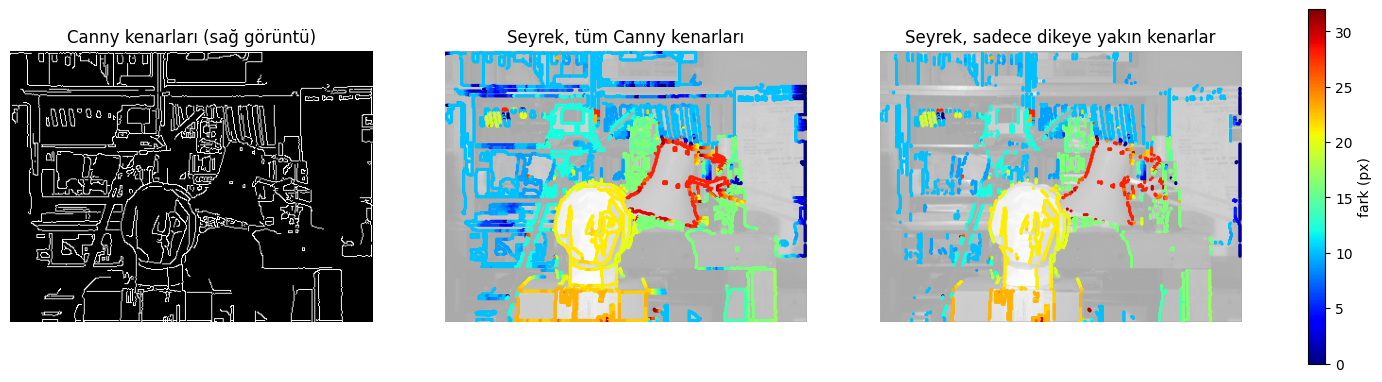

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].imshow(kenar, cmap='gray'); ax[0].set_title('Canny kenarları (sağ görüntü)'); ax[0].axis('off')
for a, ad in zip(ax[1:], seyrek):
    m = seyrek[ad][0]
    a.imshow(sag, cmap='gray', alpha=0.35)
    ys, xs = np.nonzero(np.isfinite(m))
    sc = a.scatter(xs, ys, c=m[ys, xs], cmap='jet', vmin=0, vmax=MAKS_D, s=1.5)
    a.set_xlim(0, W); a.set_ylim(H, 0); a.set_title(ad); a.axis('off')
fig.colorbar(sc, ax=list(ax), fraction=0.015, label='fark (px)')
plt.savefig(SONUC / 'ev_odevi_seyrek_stereo.png', dpi=110, bbox_inches='tight'); plt.show()

### Ev Ödevi — Seyrek ve yoğun stereo karşılaştırması

**Hız.** Canny %10,8 piksel buldu (11 954 piksel), dikeye yakın olanlar %5,5. Aynı kodla (doğrudan 9 × 9 SAD toplamı) bütün pikselleri eşleştirmek 1–1,5 s sürerken (çalıştırmaya göre değişiyor) sadece kenarları eşleştirmek ~0,11 s, dikey kenarları ~0,06 s sürdü: **yaklaşık 10 ve 20 kat hızlı**. Piksel başına süre aynı mertebede (~9–13 µs); kazanç tamamen daha az piksel hesaplamaktan geliyor, süre kenar sayısıyla doğru orantılı. Kenar bulma (Canny + Sobel) süreye dahil, birkaç ms tutuyor.

Ama yoğun yöntem integral görüntüyle yazılınca (Görev 2) pencere toplamı piksel başına O(1) oluyor ve bütün görüntü ~0,1 s'de bitiyor: seyrek yöntemle aynı süre. Seyrek eşleştirmede komşu pencereler paylaşılmadığı için her kenar pikseli için blok² toplama gerekiyor. Yani seyrek yöntemin hız avantajı, kenar oranı yaklaşık $4 / \text{blok}^2$'den küçük olduğunda ya da yoğun yöntem pahalı olduğunda (büyük blok, ZNCC, SGM, yüksek çözünürlük, gömülü sistem) gerçekten önemli oluyor. OpenCV'nin C++ yoğun eşleştiricileri (2–8 ms) ise ikisinden de çok hızlı. Burada NumPy ile C++'ı değil, aynı dilde yazılmış seyrek ve yoğun algoritmaları karşılaştırmak anlamlı.

**Doğruluk.** Aynı pikseller üzerinde seyrek yöntem, aynı maliyetle (SAD, blok 9) yoğun blok eşleştirmeyle **birebir aynı** sonucu veriyor (kenarlarda %14,9 kötü piksel). Beklenen bu: her piksel için aynı pencere aynı satırda aranıyor. Seyrek yöntem bir pikseli daha doğru eşleştirmiyor, sadece **güvenilir olacağı pikselleri seçiyor**:

- Kenar piksellerinde kötü piksel oranı (%14,9) dokusuz bölgelerin de katıldığı genel orana yakın. Çünkü kenarların bir kısmı tam derinlik süreksizliğinde ve örtülme bölgesinin yanında.
- **Dikeye yakın kenarlarda** hata %11,0'a düşüyor. Yatay kenarlar (masa kenarı gibi) satır boyunca hep aynı göründüğü için yatay aramada belirsiz; dikey kenarlar tek bir konumda eşleşiyor. Yani seyrek stereo için dikey yönlü kenarları seçmek hem daha hızlı hem daha doğru.
- Global bilgi kullanan SGM aynı kenar piksellerinde de daha iyi (%8,1, dikey kenarlarda %7,1).

Seyrek yöntemin en büyük eksiği **kapsama**: piksellerin sadece %5–11'inde değer var. Dokusuz yüzeylerin (duvar, masa üstü) derinliği hiç bilinmiyor; yoğun bir harita gerekiyorsa sonradan interpolasyon gerekir.

| | Seyrek (kenar tabanlı) | Yoğun (BM / SGM) |
| --- | --- | --- |
| Hesaplanan piksel | %5–11 | %100 (OpenCV BM %73, SGBM %88) |
| Hız (aynı algoritma, doğrudan toplam) | ~10–20 kat hızlı | yavaş |
| Hız (integral görüntülü yoğun BM ile) | yaklaşık aynı | yaklaşık aynı |
| Doğruluk (aynı maliyet, aynı pikseller) | aynı | aynı; SGM daha iyi |
| Güvenilirlik | dikey kenarlar seçilirse yüksek (%11 kötü) | dokusuz bölgelerde düşük (BM), SGM ile iyi |
| Kullanım | hızlı engel tespiti, görsel odometri, öznitelik tabanlı 3B | derinlik haritası, 3B yeniden oluşturma |

## Genel değerlendirme

| Yöntem | Kötü piksel % | Süre |
| --- | --- | --- |
| OpenCV StereoBM (blok 15) | 23,5 | ~2 ms |
| OpenCV StereoSGBM (blok 5) | 12,3 | ~8 ms |
| Kendi BM, SAD (blok 15) | 12,5 | ~100 ms |
| Kendi BM, ZNCC (blok 9), parlaklık farkıyla | 15,9 | ~330 ms |
| Kendi SGM, SAD 5 × 5, P1 = 10, P2 = 120 | 7,8 | ~200 ms |
| Seyrek, dikey kenarlar (sadece %5,5 piksel) | 11,0 (kendi piksellerinde) | ~60 ms |

- Yerel yöntemler (BM) hızlı ama dokusuz bölgelerde ve örtülmede zayıf; blok boyutu ayrıntı ile gürültü arasında bir ödünleşim.
- Maliyet seçimi kameralara bağlı: aynı pozlamada SAD, parlaklık farkı varsa ZNCC.
- Yumuşaklık terimi (SGM) en büyük iyileşmeyi sağladı; P2 doğru ayarlanmazsa ya gürültü ya da aşırı yumuşatma oluyor.
- Fark haritası kalibrasyon ($f$, $B$) olmadan sadece göreli derinlik veriyor.